# Step 2: Exploratory Data Analysis (EDA)

**Input:** `ncdb2019_collisions.csv` from `01_aggregation.ipynb` (one row per collision)

**Sections**
1. Load data and set up
2. Structure and overview
3. Missing values
4. Target distribution (class imbalance)
5. Feature distributions
6. Outlier check
7. Feature vs target relationships
8. Correlation heatmaps
9. Intersection-only subset

Code labels in section 1 are for chart readability. Verify them against the NCDB Data Dictionary.

## 1. Load data and set up

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

DATA_FILE = "ncdb2019_collisions.csv"

# If the file isn't in this Colab session, upload the CSV saved by notebook 01
if not os.path.exists(DATA_FILE):
    from google.colab import files
    uploaded = files.upload()
    DATA_FILE = list(uploaded.keys())[0]

CODE_COLS = ["C_SEV", "C_CONF", "C_RCFG", "C_WTHR", "C_RSUR", "C_RALN", "C_TRAF", "C_CASE"]
col = pd.read_csv(DATA_FILE, dtype={c: str for c in CODE_COLS})

CLASS_ORDER = ["1", "2", "3+"]
col["Casualty_Class"] = pd.Categorical(col["Casualty_Class"].astype("string"),
                                       categories=CLASS_ORDER, ordered=True)
print("Shape:", col.shape)

Saving ncdb2019_collisions.csv to ncdb2019_collisions.csv
Shape: (105782, 24)


In [2]:
# Readable labels for charts (check against the data dictionary)
LABELS = {
    "C_WTHR": {"1": "Clear", "2": "Overcast", "3": "Rain", "4": "Snow",
               "5": "Freezing rain/hail", "6": "Low visibility", "7": "Strong wind", "Q": "Other"},
    "C_RSUR": {"1": "Dry", "2": "Wet", "3": "Snow", "4": "Slush", "5": "Icy",
               "6": "Sand/gravel", "7": "Muddy", "8": "Oil", "9": "Flooded", "Q": "Other"},
    "C_RALN": {"1": "Straight, level", "2": "Straight, gradient", "3": "Curved, level",
               "4": "Curved, gradient", "5": "Top of hill", "6": "Bottom of hill", "Q": "Other"},
    "C_RCFG": {"01": "Non-intersection", "02": "Intersection", "03": "Driveway/parking",
               "04": "Railroad crossing", "05": "Bridge/overpass", "06": "Tunnel",
               "07": "Passing lane", "08": "Ramp", "09": "Traffic circle",
               "10": "Express lane", "11": "Collector lane", "12": "Transfer lane", "QQ": "Other"},
    "C_TRAF": {"01": "Signals (working)", "02": "Signals (flashing)", "03": "Stop sign",
               "04": "Yield sign", "05": "Warning sign", "06": "Ped crosswalk",
               "07": "Police officer", "08": "School guard", "09": "School crossing",
               "10": "Reduced speed zone", "11": "No passing zone", "12": "Road markings",
               "13": "School bus", "15": "Rail signals/gates", "16": "Rail signs only",
               "17": "Not specified", "18": "No control", "QQ": "Other"},
    "C_CONF": {"01": "Hit moving object", "02": "Hit stationary object", "03": "Ran off left",
               "04": "Ran off right", "05": "Rollover", "06": "Other single vehicle",
               "21": "Rear-end", "22": "Side swipe", "23": "Left turn conflict (same dir)",
               "24": "Right turn conflict (same dir)", "25": "Other same direction",
               "31": "Head-on", "32": "Approaching side swipe", "33": "Left turn across traffic",
               "34": "Right turn", "35": "Right angle", "36": "Other different direction",
               "41": "Hit parked vehicle", "QQ": "Other"},
}

def label(s, name):
    """Map codes to readable labels; unknown codes keep their raw value."""
    return s.map(lambda v: LABELS[name].get(v, v) if pd.notna(v) else "Missing")

CAT_FEATURES = ["C_RCFG", "C_TRAF", "C_WTHR", "C_RSUR", "C_RALN", "C_CONF"]
NUM_FEATURES = ["C_HOUR", "C_WDAY", "C_MNTH", "C_VEHS"]
BIN_FEATURES = ["Heavy_Vehicle_Present", "Cyclist_Present", "Safety_Device_Not_Used"]
FEATURES = CAT_FEATURES + NUM_FEATURES + BIN_FEATURES   # the 13 candidate features
TARGET = "Casualty_Class"

# Built from the target: EDA only, never used as model inputs (data leakage)
LEAKAGE = ["Total_Injuries", "Total_Fatalities", "Total_Casualties", "Fatal_Collision", "C_SEV"]

## 2. Structure and overview

In [3]:
print(f"Collisions: {len(col):,}   Columns: {col.shape[1]}")
overview = pd.DataFrame({
    "dtype": col[FEATURES + [TARGET]].dtypes.astype(str),
    "n_unique": col[FEATURES + [TARGET]].nunique(),
    "pct_missing": (col[FEATURES + [TARGET]].isna().mean() * 100).round(2),
})
overview

Collisions: 105,782   Columns: 24


,dtype,n_unique,pct_missing
C_RCFG,object,11,5.71
C_TRAF,object,18,5.49
C_WTHR,object,8,1.42
C_RSUR,object,10,0.97
C_RALN,object,7,5.07
C_CONF,object,19,3.26
C_HOUR,float64,24,0.81
C_WDAY,float64,7,0.00
C_MNTH,float64,12,0.00
C_VEHS,int64,29,0.00


In [4]:
col[NUM_FEATURES + BIN_FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
C_HOUR,104922.0,13.49,5.17,0.0,10.0,14.0,17.0,23.0
C_WDAY,105781.0,3.88,1.92,1.0,2.0,4.0,5.0,7.0
C_MNTH,105781.0,6.66,3.47,1.0,4.0,7.0,10.0,12.0
C_VEHS,105782.0,1.81,0.84,1.0,1.0,2.0,2.0,70.0
Heavy_Vehicle_Present,105782.0,0.01,0.11,0.0,0.0,0.0,0.0,1.0
Cyclist_Present,105782.0,0.04,0.20,0.0,0.0,0.0,0.0,1.0
Safety_Device_Not_Used,3991.0,0.41,0.49,0.0,0.0,0.0,1.0,1.0


## 3. Missing values

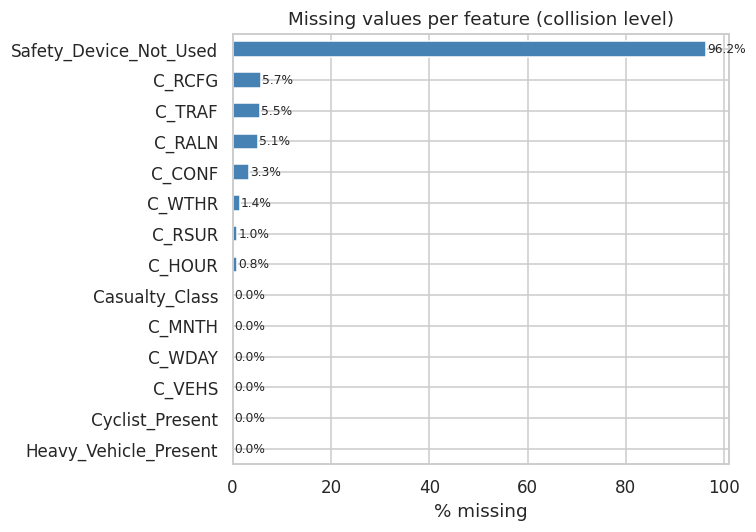

In [5]:
miss = (col[FEATURES + [TARGET]].isna().mean() * 100).sort_values()
ax = miss.plot.barh(figsize=(7, 5), color="steelblue")
ax.set_xlabel("% missing")
ax.set_title("Missing values per feature (collision level)")
for i, v in enumerate(miss):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout(); plt.show()

In [6]:
# Rows left if every row with any missing feature/target is dropped
complete = col.dropna(subset=FEATURES + [TARGET])
print(f"Complete cases: {len(complete):,} of {len(col):,} ({len(complete)/len(col)*100:.1f}%)")
print("Project minimum is 50,000 records.")

Complete cases: 3,681 of 105,782 (3.5%)
Project minimum is 50,000 records.


In [7]:
# Is missingness related to the target? If yes, an 'Unknown' category may carry information.
d = col.dropna(subset=[TARGET])
rows = []
for f in FEATURES:
    m = d[f].isna()
    if m.sum() == 0:
        continue
    rows.append({
        "feature": f,
        "n_missing": int(m.sum()),
        "% 3+ when missing": round((d.loc[m, TARGET] == "3+").mean() * 100, 2),
        "% 3+ when present": round((d.loc[~m, TARGET] == "3+").mean() * 100, 2),
    })
pd.DataFrame(rows).sort_values("n_missing", ascending=False)

,feature,n_missing,% 3+ when missing,% 3+ when present
9,Safety_Device_Not_Used,101790,6.79,8.22
0,C_RCFG,6037,4.62,6.98
1,C_TRAF,5810,5.46,6.93
4,C_RALN,5363,4.44,6.97
5,C_CONF,3448,4.90,6.91
2,C_WTHR,1505,4.45,6.88
3,C_RSUR,1022,4.21,6.87
6,C_HOUR,860,4.53,6.87
7,C_WDAY,1,0.00,6.85
8,C_MNTH,1,0.00,6.85


## 4. Target distribution (class imbalance)

Rows with no class (0 known casualties): 1


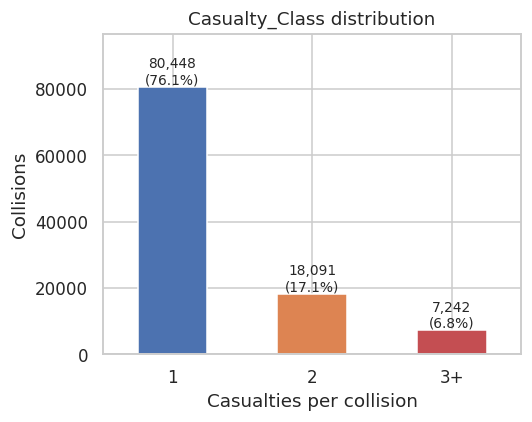

Imbalance ratio (largest / smallest class): 11.1


In [8]:
print("Rows with no class (0 known casualties):", col[TARGET].isna().sum())
counts = col[TARGET].value_counts().reindex(CLASS_ORDER)
pct = counts / counts.sum() * 100

ax = counts.plot.bar(figsize=(5, 4), color=["#4C72B0", "#DD8452", "#C44E52"], rot=0)
ax.set_xlabel("Casualties per collision"); ax.set_ylabel("Collisions")
ax.set_title("Casualty_Class distribution")
for i, (c, p) in enumerate(zip(counts, pct)):
    ax.text(i, c, f"{c:,}\n({p:.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout(); plt.show()

print(f"Imbalance ratio (largest / smallest class): {counts.max() / counts.min():.1f}")

## 5. Feature distributions

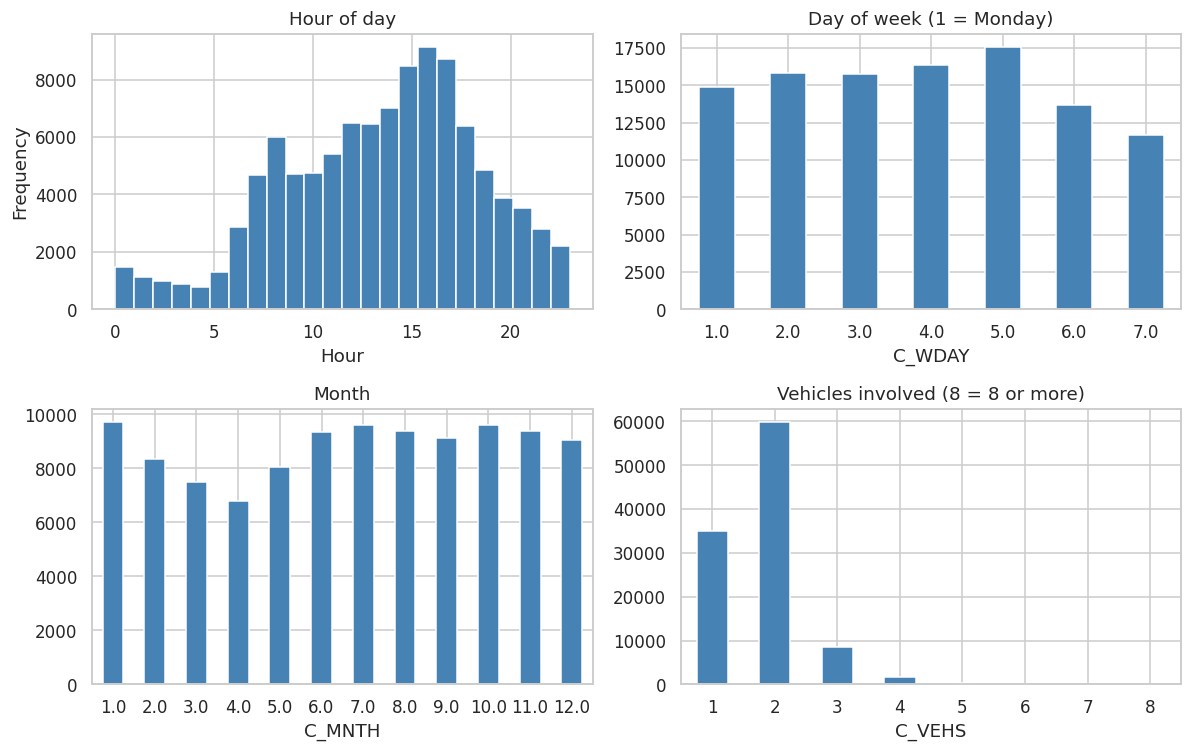

In [9]:
# Numeric / time features
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
col["C_HOUR"].plot.hist(bins=24, ax=axes[0, 0], color="steelblue", edgecolor="white")
axes[0, 0].set_title("Hour of day"); axes[0, 0].set_xlabel("Hour")

col["C_WDAY"].value_counts().sort_index().plot.bar(ax=axes[0, 1], color="steelblue", rot=0)
axes[0, 1].set_title("Day of week (1 = Monday)")

col["C_MNTH"].value_counts().sort_index().plot.bar(ax=axes[1, 0], color="steelblue", rot=0)
axes[1, 0].set_title("Month")

col["C_VEHS"].clip(upper=8).value_counts().sort_index().plot.bar(ax=axes[1, 1], color="steelblue", rot=0)
axes[1, 1].set_title("Vehicles involved (8 = 8 or more)")
plt.tight_layout(); plt.show()

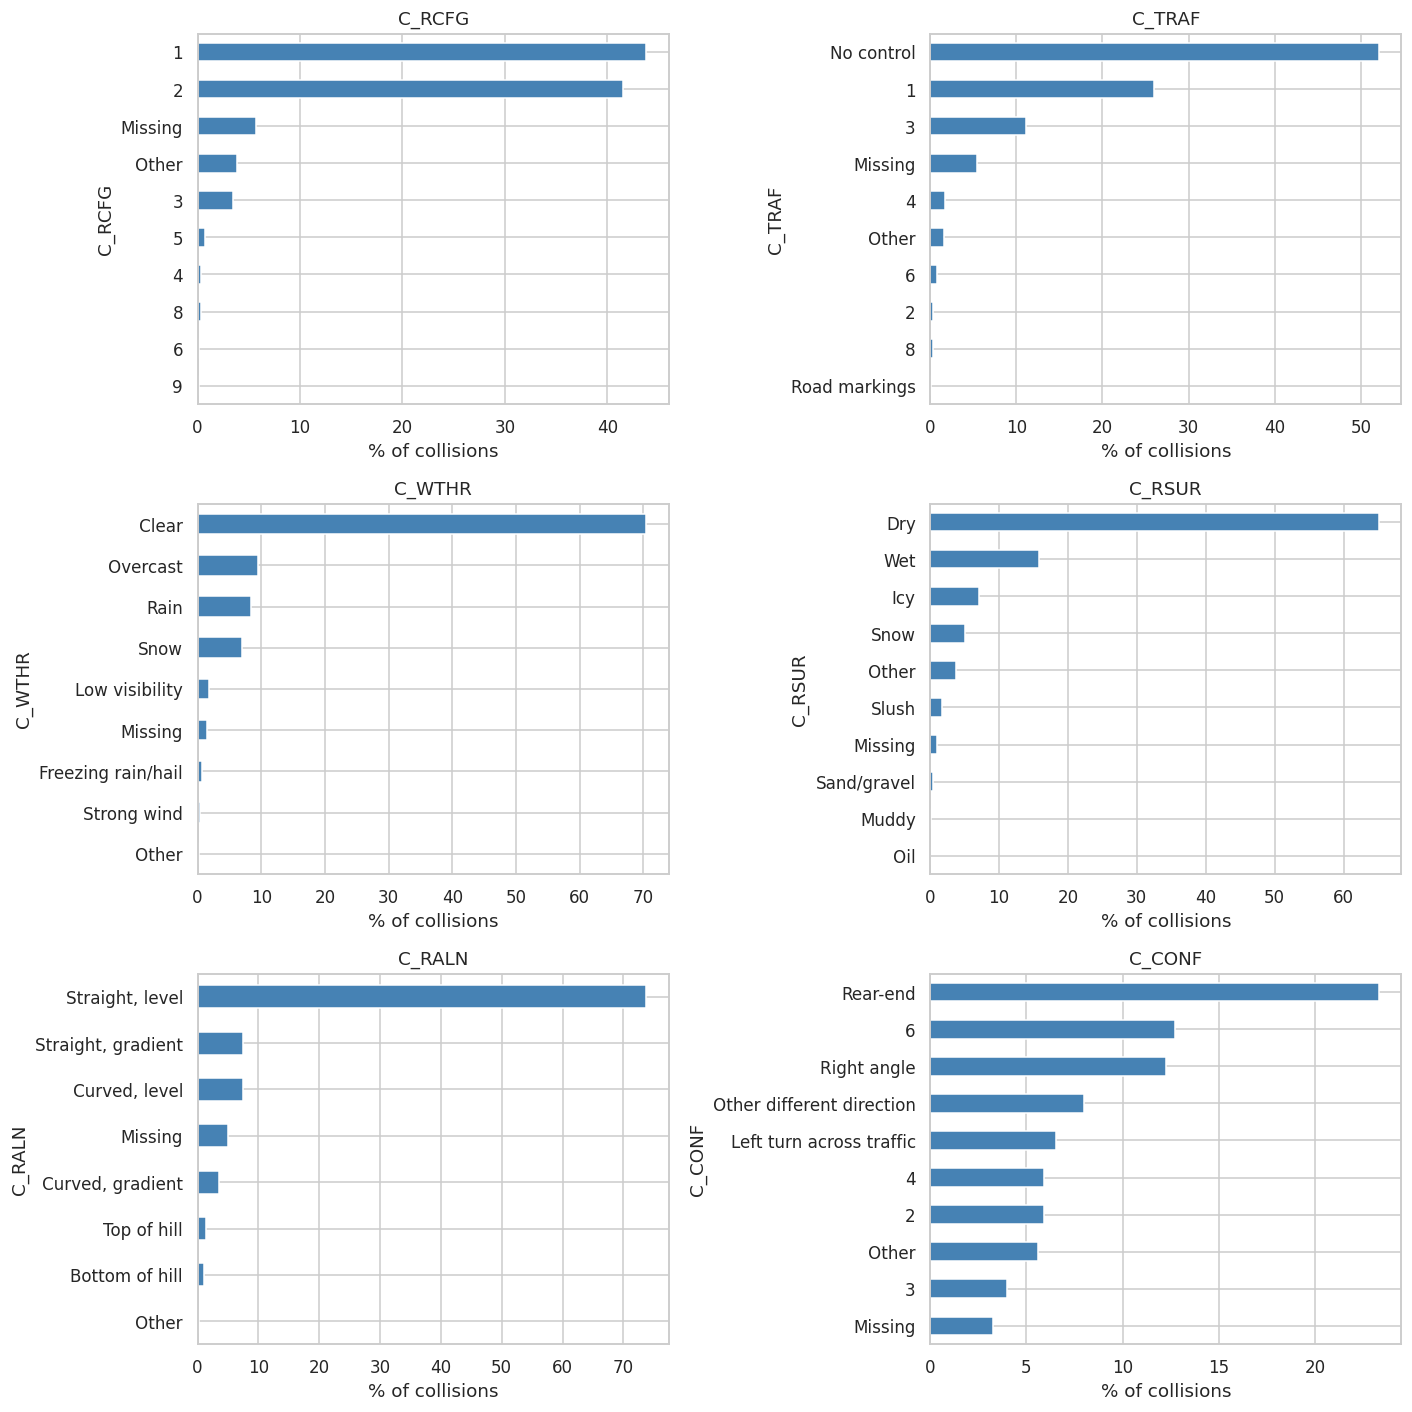

In [10]:
# Categorical features (top 10 categories each, including Missing)
fig, axes = plt.subplots(3, 2, figsize=(13, 13))
for ax, f in zip(axes.ravel(), CAT_FEATURES):
    vc = label(col[f], f).value_counts(normalize=True).head(10) * 100
    vc.sort_values().plot.barh(ax=ax, color="steelblue")
    ax.set_title(f); ax.set_xlabel("% of collisions")
plt.tight_layout(); plt.show()

In [11]:
# Binary features
(col[BIN_FEATURES].mean() * 100).round(2).rename("% of collisions = 1").to_frame()

,% of collisions = 1
Heavy_Vehicle_Present,1.21
Cyclist_Present,4.31
Safety_Device_Not_Used,41.17


## 6. Outlier check (numeric features)

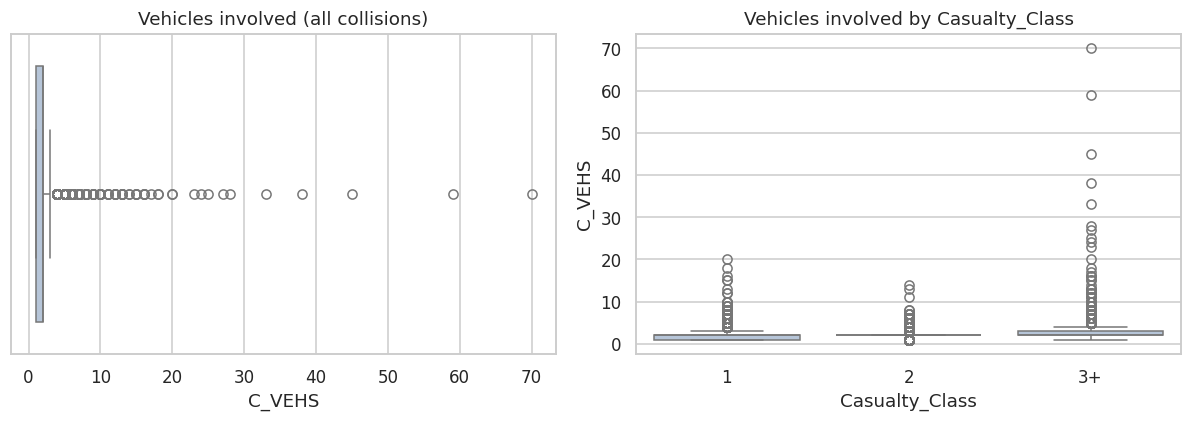

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=col["C_VEHS"], ax=axes[0], color="lightsteelblue")
axes[0].set_title("Vehicles involved (all collisions)")

sns.boxplot(data=col.dropna(subset=[TARGET]), x=TARGET, y="C_VEHS",
            order=CLASS_ORDER, ax=axes[1], color="lightsteelblue")
axes[1].set_title("Vehicles involved by Casualty_Class")
plt.tight_layout(); plt.show()

In [13]:
q1, q3 = col["C_VEHS"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
out = col["C_VEHS"] > upper
print(f"IQR upper fence: {upper:.1f} vehicles")
print(f"Collisions above fence: {out.sum():,} ({out.mean()*100:.2f}%)")
print("\nLargest vehicle counts:")
print(col["C_VEHS"].value_counts().sort_index().tail(10))
print("\nClass mix of outlier collisions (%):")
print((col.loc[out, TARGET].value_counts(normalize=True) * 100).round(1))

IQR upper fence: 3.5 vehicles
Collisions above fence: 2,381 (2.25%)

Largest vehicle counts:
C_VEHS
23    1
24    1
25    1
27    1
28    1
33    1
38    1
45    1
59    1
70    1
Name: count, dtype: int64

Class mix of outlier collisions (%):
Casualty_Class
1     49.4
2     27.0
3+    23.6
Name: proportion, dtype: float64


## 7. Feature vs target relationships

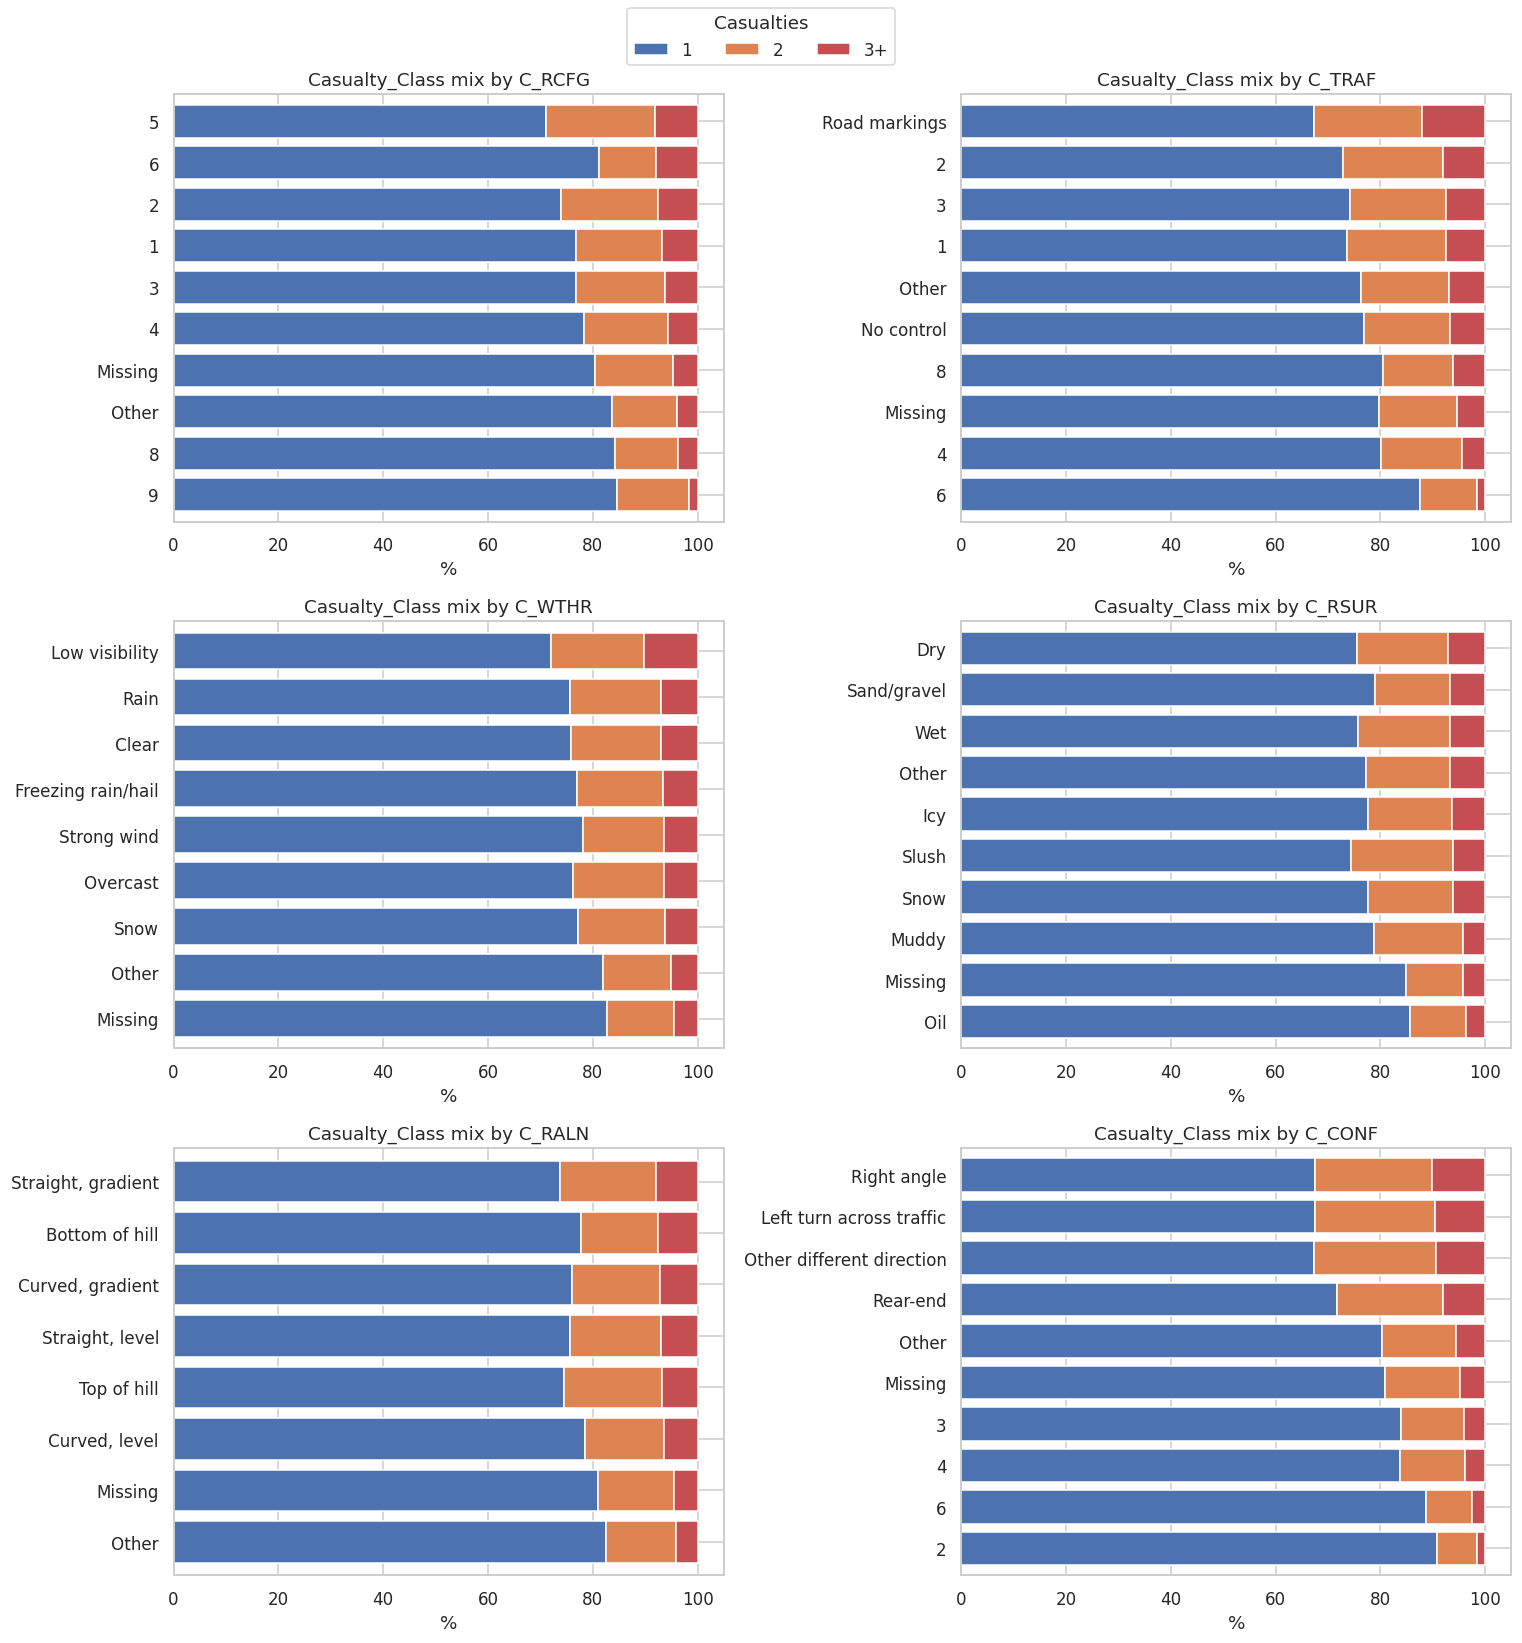

In [14]:
def stacked_by_class(f, top=10, ax=None):
    """100% stacked bars: class mix within each category (most common categories)."""
    d = col.dropna(subset=[TARGET]).copy()
    d[f] = label(d[f], f) if f in LABELS else d[f].astype(str)
    keep = d[f].value_counts().head(top).index
    tab = pd.crosstab(d.loc[d[f].isin(keep), f], d[TARGET], normalize="index") * 100
    tab = tab.reindex(columns=CLASS_ORDER).sort_values("3+")   # highest 3+ share on top
    tab.plot.barh(stacked=True, ax=ax, color=["#4C72B0", "#DD8452", "#C44E52"],
                  width=0.8, legend=False)
    ax.set_title(f"Casualty_Class mix by {f}"); ax.set_xlabel("%"); ax.set_ylabel("")

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
for ax, f in zip(axes.ravel(), CAT_FEATURES):
    stacked_by_class(f, ax=ax)
handles, labels_ = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels_, title="Casualties", loc="upper center", ncol=3)
plt.tight_layout(rect=[0, 0, 1, 0.97]); plt.show()

In [15]:
# % of collisions with 3+ casualties, by binary feature
d = col.dropna(subset=[TARGET])
rows = []
for f in BIN_FEATURES:
    for v in [0, 1]:
        s = d[d[f] == v]
        rows.append({"feature": f, "value": v, "n": len(s),
                     "% 3+": round((s[TARGET] == "3+").mean() * 100, 2)})
pd.DataFrame(rows)

,feature,value,n,% 3+
0,Heavy_Vehicle_Present,0,104501,6.85
1,Heavy_Vehicle_Present,1,1280,6.80
2,Cyclist_Present,0,101222,7.14
3,Cyclist_Present,1,4559,0.24
4,Safety_Device_Not_Used,0,2348,9.45
5,Safety_Device_Not_Used,1,1643,6.45


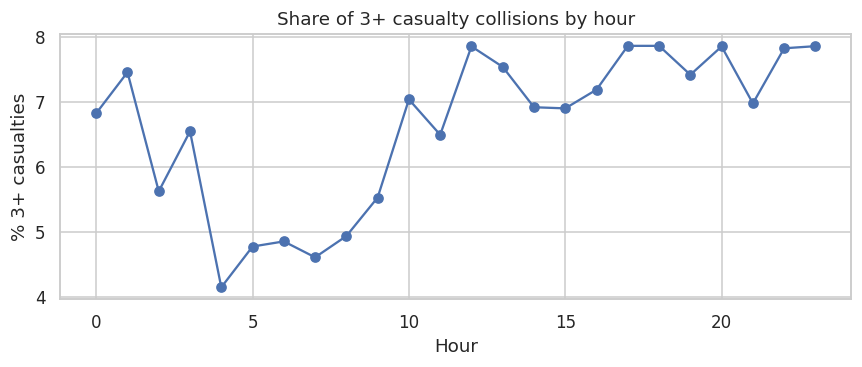

In [16]:
# % 3+ by hour of day
d = col.dropna(subset=[TARGET, "C_HOUR"])
rate = d.groupby("C_HOUR")[TARGET].apply(lambda s: (s == "3+").mean() * 100)
ax = rate.plot(marker="o", figsize=(8, 3.5))
ax.set_xlabel("Hour"); ax.set_ylabel("% 3+ casualties")
ax.set_title("Share of 3+ casualty collisions by hour")
plt.tight_layout(); plt.show()

## 8. Correlation heatmaps

Most features are categorical, so Pearson correlation is not meaningful for them.
**Cramér's V** (0 = no association, 1 = perfect association) is used for all feature pairs and the target.
Numeric features are binned/treated as categories for this. A Spearman heatmap is added for the numeric/binary features.

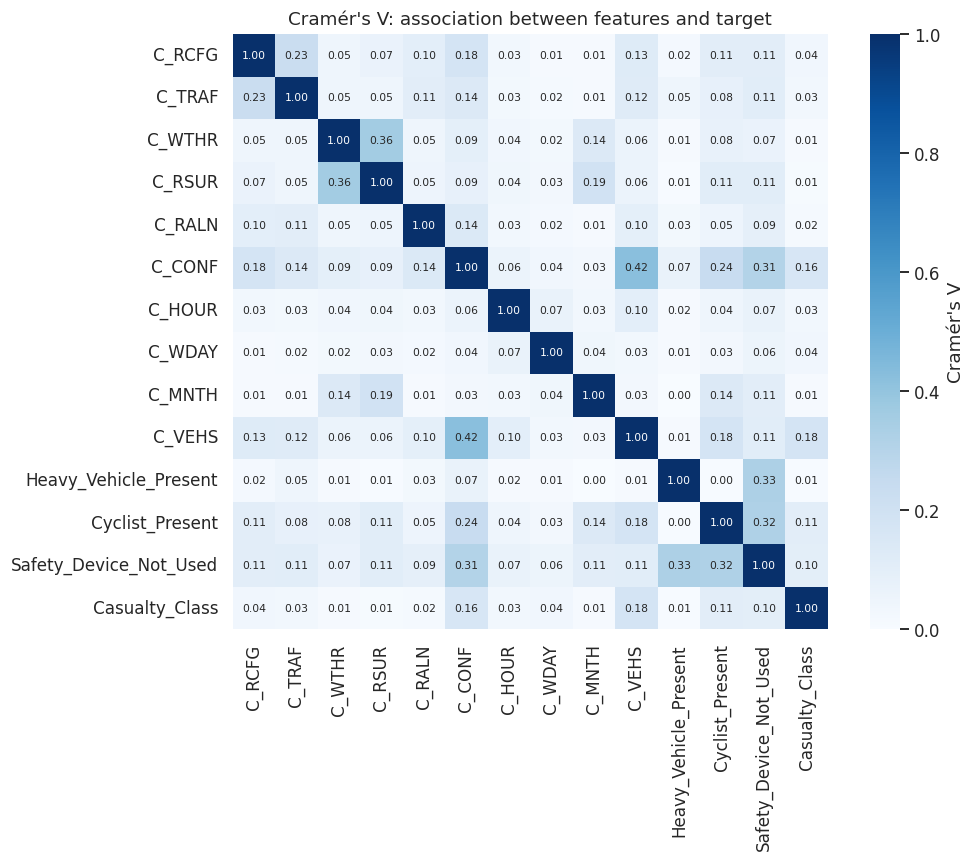

In [17]:
def cramers_v(x, y):
    """Bias-corrected Cramér's V between two categorical series."""
    tab = pd.crosstab(x, y)
    if tab.shape[0] < 2 or tab.shape[1] < 2:
        return np.nan
    chi2 = chi2_contingency(tab, correction=False)[0]
    n = tab.values.sum()
    phi2 = chi2 / n
    r, k = tab.shape
    phi2c = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2c / max(1e-12, min(kc - 1, rc - 1)))

cv_df = col[FEATURES + [TARGET]].copy()
cv_df["C_VEHS"] = cv_df["C_VEHS"].clip(upper=6)   # 6 = 6 or more
cv_cols = FEATURES + [TARGET]

cv = pd.DataFrame(index=cv_cols, columns=cv_cols, dtype=float)
for i, a in enumerate(cv_cols):
    for b in cv_cols[i:]:
        sub = cv_df[[a, b]].dropna()
        v = 1.0 if a == b else cramers_v(sub[a].astype(str), sub[b].astype(str))
        cv.loc[a, b] = cv.loc[b, a] = v

plt.figure(figsize=(10, 8))
sns.heatmap(cv, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True,
            cbar_kws={"label": "Cramér's V"}, annot_kws={"size": 7})
plt.title("Cramér's V: association between features and target")
plt.tight_layout(); plt.show()

In [18]:
# Strongest feature-feature pairs (possible redundancy) and feature-target associations
pairs = (cv.loc[FEATURES, FEATURES].where(np.triu(np.ones((len(FEATURES),) * 2), 1).astype(bool))
         .stack().sort_values(ascending=False))
print("Top feature pairs:\n", pairs.head(8).round(3))
print("\nAssociation with target:\n", cv.loc[FEATURES, TARGET].sort_values(ascending=False).round(3))

Top feature pairs:
 C_CONF                 C_VEHS                    0.425
C_WTHR                 C_RSUR                    0.361
Heavy_Vehicle_Present  Safety_Device_Not_Used    0.331
Cyclist_Present        Safety_Device_Not_Used    0.324
C_CONF                 Safety_Device_Not_Used    0.310
                       Cyclist_Present           0.240
C_RCFG                 C_TRAF                    0.231
C_RSUR                 C_MNTH                    0.193
dtype: float64

Association with target:
 C_VEHS                    0.178
C_CONF                    0.161
Cyclist_Present           0.106
Safety_Device_Not_Used    0.104
C_RCFG                    0.038
C_WDAY                    0.037
C_TRAF                    0.034
C_HOUR                    0.034
C_RALN                    0.017
C_MNTH                    0.015
C_WTHR                    0.014
C_RSUR                    0.011
Heavy_Vehicle_Present     0.007
Name: Casualty_Class, dtype: float64


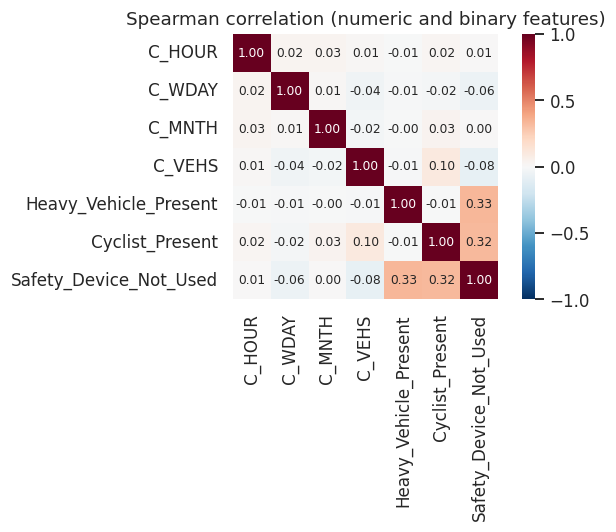

In [19]:
sp_cols = NUM_FEATURES + BIN_FEATURES
plt.figure(figsize=(6.5, 5))
sns.heatmap(col[sp_cols].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1, square=True, annot_kws={"size": 8})
plt.title("Spearman correlation (numeric and binary features)")
plt.tight_layout(); plt.show()

## 9. Intersection-only subset

The project title focuses on intersections. This compares the full dataset with intersection collisions only
(`Is_Intersection` = road configuration 02, 03 or 09) to help decide whether to filter.

In [20]:
inter = col[col["Is_Intersection"] == 1]
comp = pd.DataFrame({
    "All collisions (%)": col[TARGET].value_counts(normalize=True).reindex(CLASS_ORDER) * 100,
    "Intersection only (%)": inter[TARGET].value_counts(normalize=True).reindex(CLASS_ORDER) * 100,
}).round(2)
print(f"All collisions: {len(col):,}   Intersection only: {len(inter):,}")
print(f"Intersection-only complete cases: {len(inter.dropna(subset=FEATURES + [TARGET])):,}")
comp

All collisions: 105,782   Intersection only: 0
Intersection-only complete cases: 0


,All collisions (%),Intersection only (%)
Casualty_Class,,
1,76.05,NaN
2,17.10,NaN
3+,6.85,NaN


## Notes for the preprocessing step
Things to look at in the outputs above before deciding on preprocessing:
- Missing %: which features are small enough to drop/impute vs. large enough to keep as "Unknown"
- Whether missingness is linked to the target (section 3 table)
- Complete-case count vs. the 50,000 minimum
- Vehicle-count outliers: errors or real pileups?
- Class imbalance ratio (affects stratified split and class weights)
- Highly associated feature pairs (possible redundancy)
- Whether to filter to intersections only